# 05 · Fenotipo residual, ¿hay un segundo diagnóstico?

## Pregunta biológica

**¿Qué rasgos del paciente NO explica MVA, y alguno exige un segundo diagnóstico?**

Importa porque la nefrocalcinosis está **presente desde el nacimiento**. La del prematuro es
adquirida y postnatal (se desarrolla en semanas de furosemida, nutrición parenteral y carga de
calcio). Si está al nacer es antenatal, y **el prior se invierte**.

## La trampa que este notebook existe para evitar

El modo B midió que varios rasgos aportan poco soporte semántico al modelo MVA. La lectura
tentadora sería: *«MVA no los explica, luego hay un segundo diagnóstico»*.

**Sería convertir la incompletitud de una base de datos en biología.** El retraso de
crecimiento aparece en el **93,5 %** de los casos de MVA1: no es un residual misterioso.

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


In [2]:
fl.labels("Interpretacion", "Sesgos que no se corrigen")

## Método · la pregunta correcta no es el score, es la pertenencia

La contribución *leave-one-out* **no** es el soporte absoluto de un término: con Best Match
Average, retirar un término que puntúa por debajo de la media **sube** el promedio. Así que la
medida correcta es **si el término está anotado en el modelo de enfermedad**.

In [3]:
PREP = pickle.load(io.open("work/hpo/prepared.pkl", "rb"))
mva = [m for m in PREP["models"] if m.disease_id == "OMIM:257300"]
terms = mva[0].terms if mva else set()
print(f"  modelo OMIM:257300 (MVA1) · {mva[0].n_raw} terminos anotados antes de propagar")

PROBAND = [
 ("HP:0002859", "Rabdomiosarcoma",           "38,7 % (malignidad)"),
 ("HP:0004322", "Talla baja",                "93,5 % (crecimiento)"),
 ("HP:0001518", "Pequeno para edad gest.",   "93,5 % (crecimiento)"),
 ("HP:0001508", "Fallo de medro",            "93,5 % (crecimiento)"),
 ("HP:0001622", "Parto prematuro",           "no cuantificado"),
 ("HP:0003202", "Atrofia muscular",          "no cuantificado"),
 ("HP:0000121", "Nefrocalcinosis",           "NO, la serie reporta disfuncion renal generica 12,9 %"),
]
print()
print(f"  {'rasgo':<26}{'anotado en HPO':>16}{'literatura MVA1':>44}")
for hid, lab, lit in PROBAND:
    print(f"  {lab:<26}{('SI' if hid in terms else 'NO'):>16}{lit:>44}")

  modelo OMIM:257300 (MVA1) · 59 terminos anotados antes de propagar

  rasgo                       anotado en HPO                             literatura MVA1
  Rabdomiosarcoma                         SI                         38,7 % (malignidad)
  Talla baja                              SI                        93,5 % (crecimiento)
  Pequeno para edad gest.                 SI                        93,5 % (crecimiento)
  Fallo de medro                          NO                        93,5 % (crecimiento)
  Parto prematuro                         NO                             no cuantificado
  Atrofia muscular                        NO                             no cuantificado
  Nefrocalcinosis                         NONO, la serie reporta disfuncion renal generica 12,9 %


### Figura principal 1 · matriz término × modelo de enfermedad

La barra de «anotado sí / no» responde en binario a una pregunta que no lo es. La medida
correcta es la que usa el propio motor: **Resnik**, el contenido de información del ancestro
común más informativo entre el término del probando y el término mejor emparejado del modelo,
en bits.

> **Por qué no se clasifica por «ancestro».** Los modelos del corpus llevan sus términos
> **propagados hacia la raíz**. Con esa representación, «el modelo anota un ancestro» es cierto
> siempre (la raíz está en todos), así que esa categoría no distingue nada. Se probó, salió
> uniforme, y por eso está descartada. Lo que sí distingue: si el término **está cubierto**
> (anotado, o anotado en algo más específico) y **cuántos bits** vale el mejor emparejamiento.

In [4]:
from src.phenotype.semantic import ancestors

PAR, IC, NAMES = PREP["parents"], PREP["ic"], PREP["names"]
MODELS = PREP["models"]
cache = {}
PT = [p[0] for p in PROBAND]

def bestmatch(t, m):
    """Resnik: IC del ancestro comun mas informativo, sobre el mejor termino
    del modelo. Es exactamente el ingrediente del BMA que usa el ranking."""
    at = ancestors(t, PAR, cache)
    best = 0.0
    for mt in m.terms:
        sh = at & ancestors(mt, PAR, cache)
        if sh:
            v = max(IC.get(a, 0.0) for a in sh)
            if v > best:
                best = v
    return best

MVA_IDS = ["OMIM:257300", "OMIM:614114", "OMIM:617598"]
byid = {}
for m in MODELS:
    byid.setdefault(m.disease_id, m)

# Columnas SIN eleccion manual: los tres modelos de MVA, y despues los que mas
# se parecen al perfil COMPLETO del probando por BMA.
from src.phenotype.semantic import resnik_bma
scored = sorted(((resnik_bma(PT, m.terms, IC, PAR, cache), m) for m in byid.values()),
                key=lambda x: -x[0])
COLS, seen_id = [], set()
for did in MVA_IDS:
    if did in byid:
        COLS.append(byid[did]); seen_id.add(did)
for sc, m in scored:
    if len(COLS) >= 12:
        break
    if m.disease_id not in seen_id:
        COLS.append(m); seen_id.add(m.disease_id)
SC = {m.disease_id: resnik_bma(PT, m.terms, IC, PAR, cache) for m in COLS}

BM = np.array([[bestmatch(t, m) for m in COLS] for t in PT])
COV = np.array([[t in m.terms for m in COLS] for t in PT])
ICT = {t: IC.get(t, 0.0) for t in PT}

print(f"  modelos de enfermedad distintos en el corpus : {len(byid):,}")
print(f"  columnas: {len(COLS)}  ({len(MVA_IDS)} de MVA + "
      f"{len(COLS)-len(MVA_IDS)} por similitud al perfil completo)")
print(f"  IC maximo del corpus: {max(IC.values()):.2f} bits")
print()
print(f"  {'rasgo':<26}{'IC propio':>10}   " +
      "".join(f"{m.disease_id.split(':')[1][:6]:>8}" for m in COLS))
for i, (hid, lab, _l) in enumerate(PROBAND):
    fila = "".join(f"{BM[i][j]:>7.1f}{'*' if COV[i][j] else ' '}" for j in range(len(COLS)))
    print(f"  {lab:<26}{ICT[hid]:>10.2f}   {fila}")
print("  (* = el termino esta CUBIERTO por el modelo: anotado, o anotado en algo mas especifico)")

  modelos de enfermedad distintos en el corpus : 9,155
  columnas: 12  (3 de MVA + 9 por similitud al perfil completo)
  IC maximo del corpus: 8.57 bits

  rasgo                      IC propio     257300  614114  617598  218040  241200  601678  256810   89938  615471  105650  621184  301118
  Rabdomiosarcoma                 5.52       5.5*    0.6     2.7     5.5*    0.6     0.6     1.7     0.6     0.6     3.5     1.7     1.7 
  Talla baja                      1.27       1.3*    1.3*    1.3*    1.3*    1.3*    1.3*    1.3*    0.6     1.3*    1.3*    1.3*    1.0 
  Pequeno para edad gest.         2.85       2.8*    2.8*    0.6     1.1     2.8*    2.8*    2.8*    2.8*    2.8*    1.1     2.8*    1.0 
  Fallo de medro                  1.50       1.1     1.1     0.6     1.5*    1.5*    1.5*    1.5*    1.5*    1.5*    1.5*    1.5*    1.0 
  Parto prematuro                 3.28       1.6     0.0     0.0     3.3*    3.3*    3.3*    0.0     3.3*    3.3*    3.3*    3.3*    3.3*
  Atrofia muscular

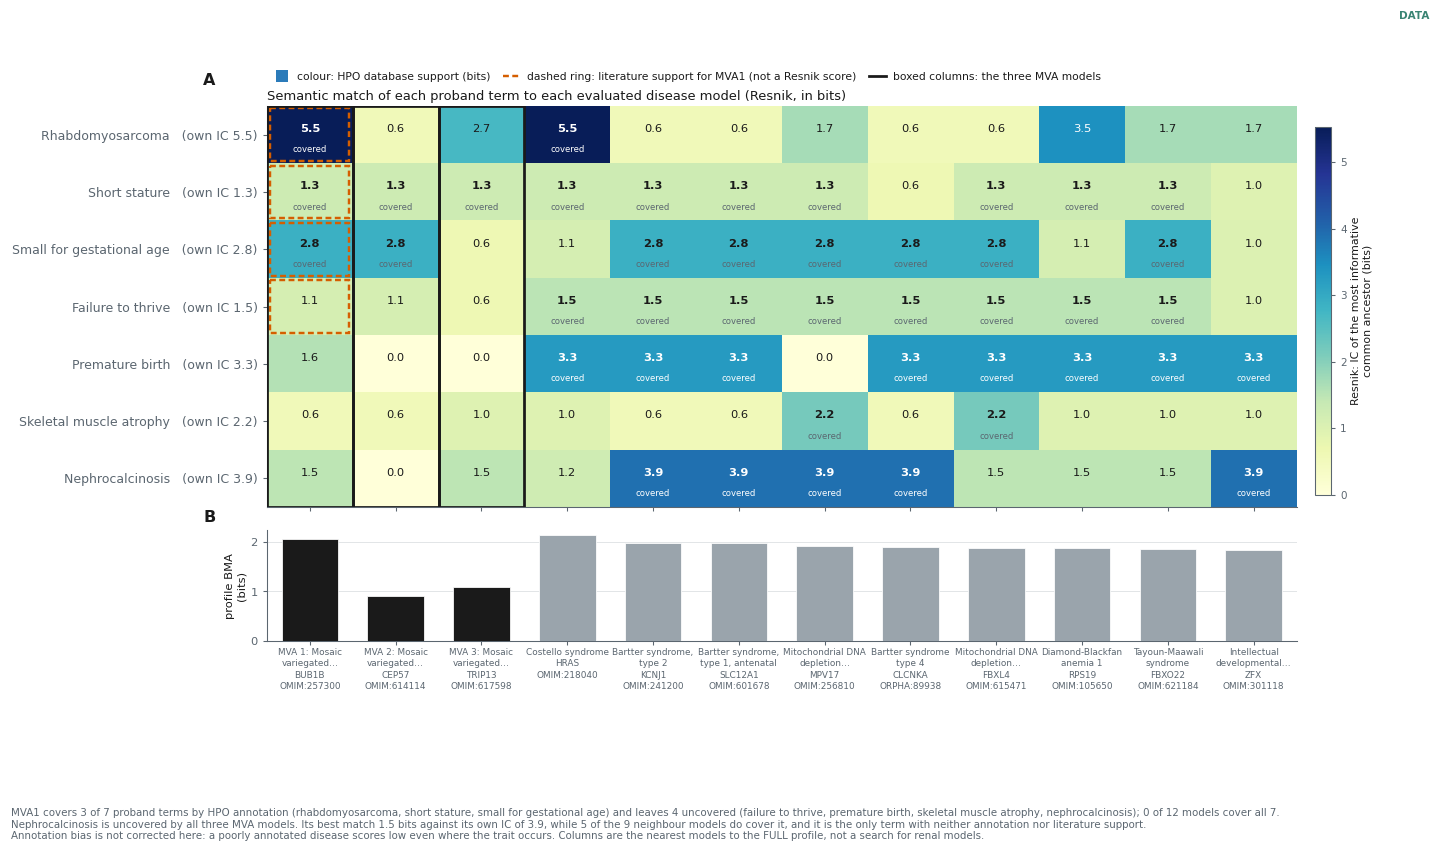

> **Figura principal 1 · matriz termino HPO x modelo de enfermedad**  
> `EXP-018 · EXP-019` · figure class `DATA`, figura cientifica · evidence origin `EXTERNAL+DERIVED`  
> *Interpretacion.* donde encaja y donde no encaja cada rasgo, en bits y no en si/no, contra los 12 modelos evaluados con su nombre de enfermedad real. MVA1 cubre 3 de los 7 rasgos y deja 4 sin cubrir. La nefrocalcinosis no la cubre ninguno de los tres modelos de MVA. Su mejor emparejamiento 1.5 bits sobre un IC propio de 3.9, mientras que los modelos de Bartter si. El anillo discontinuo marca el soporte de LITERATURA de MVA1, que se mantiene separado del color y NUNCA se convierte en un score.  
> **Sesgos que no se corrigen.** que haga falta un segundo diagnostico. El IC lo fija el corpus: una enfermedad poco anotada puntua bajo aunque el rasgo ocurra en ella. Las columnas son los vecinos del perfil COMPLETO, no una busqueda de modelos renales.  
> datos: `work/hpo/prepared.pkl + work/hpo/phenotype.hpoa (nombres de enfermedad)` · libreria: `matplotlib` · procedencia: `figures/pub/fig05_hpo_disease_matrix.svg + .png 300 dpi`

In [5]:
from src.figures import fig05_hpo as FH

MTX = FH.prepare([t for t, _l in FH.PROBAND], dict(FH.PROBAND), FH.LIT_MVA1)
fig = FH.build(MTX)
_pt, _cov, _bm = MTX["terms"], MTX["covered"], MTX["bestmatch"]
_mv = [j for j, c in enumerate(MTX["cols"]) if c["id"] in FH.MVA_IDS]
_cov1 = [MTX["term_labels"][_pt[i]] for i in range(len(_pt)) if _cov[i, _mv[0]]]
_unc1 = [MTX["term_labels"][_pt[i]] for i in range(len(_pt)) if not _cov[i, _mv[0]]]
_inef = MTX["nephro_index"]
fl.pub(fig, "Figura principal 1 · matriz termino HPO x modelo de enfermedad",
       "EXP-018 · EXP-019", "EXTERNAL+DERIVED", "DATA",
       f"donde encaja y donde no encaja cada rasgo, en bits y no en si/no, contra los "
       f"{len(MTX['cols'])} modelos evaluados con su nombre de enfermedad real. MVA1 cubre "
       f"{len(_cov1)} de los {len(_pt)} rasgos y deja {len(_unc1)} sin cubrir. La "
       f"nefrocalcinosis no la cubre ninguno de los tres modelos de MVA. Su mejor "
       f"emparejamiento {_bm[_inef, _mv[0]]:.1f} bits sobre un IC propio de "
       f"{MTX['ic_terms'][_pt[_inef]]:.1f}, mientras que los modelos de Bartter si. El anillo "
       f"discontinuo marca el soporte de LITERATURA de MVA1, que se mantiene separado del "
       f"color y NUNCA se convierte en un score.",
       "que haga falta un segundo diagnostico. El IC lo fija el corpus: una enfermedad poco "
       "anotada puntua bajo aunque el rasgo ocurra en ella. Las columnas son los vecinos del "
       "perfil COMPLETO, no una busqueda de modelos renales.",
       source="work/hpo/prepared.pkl + work/hpo/phenotype.hpoa (nombres de enfermedad)",
       lib="matplotlib", slug="fig05_hpo_disease_matrix")

### Figura principal 2 · las dos comprobaciones, cruzadas

Un rasgo solo es **residual de verdad** si falla las **dos**: no anotado en el modelo HPO **y**
no respaldado por la literatura de MVA1.

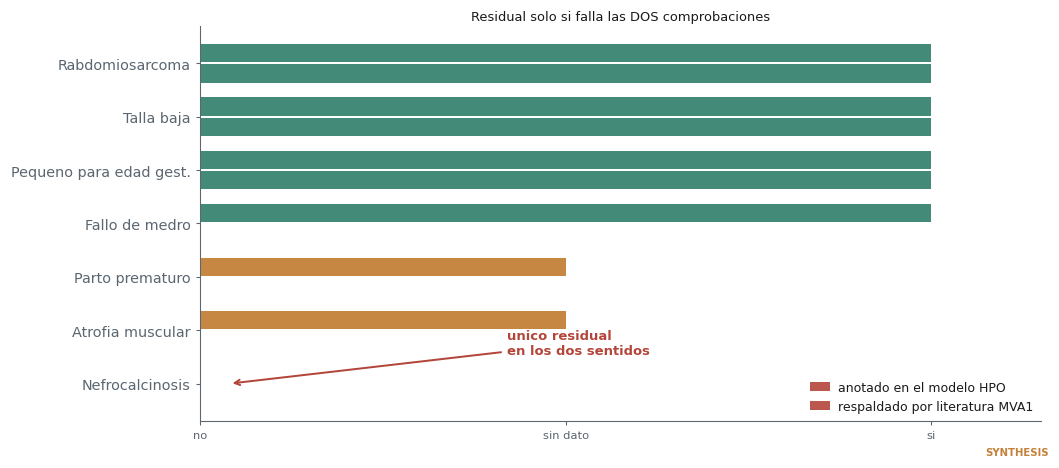

> **Figura principal 2 · anotacion HPO frente a literatura**  
> `EXP-018 · EXP-019` · figure class `SYNTHESIS`, no es un dato: synthesis · evidence origin `EXTERNAL`  
> *Interpretacion.* de los cuatro rasgos con bajo soporte semantico, tres se explican por hueco de anotacion o falta de dato. Fallo de medro NO esta anotado pero la literatura lo cubre al 93,5 %. Solo la nefrocalcinosis carece de anotacion Y de respaldo.  
> **Sesgos que no se corrigen.** que la nefrocalcinosis exija un segundo diagnostico. Que MVA no la describa no implica que no pueda causarla: las series son pequenas y con sesgo de publicacion.  
> procedencia: `corpus HPO local + Neurol Sci 2022, DOI 10.1007/s10072-022-06247-w`

In [6]:
LITOK = {"HP:0002859": 1, "HP:0004322": 1, "HP:0001518": 1, "HP:0001508": 1,
         "HP:0001622": 0.5, "HP:0003202": 0.5, "HP:0000121": 0}
fig, ax = plt.subplots(figsize=(9.6, 4.2))
labels = [p[1] for p in PROBAND][::-1]
ann = [1 if p[0] in terms else 0 for p in PROBAND][::-1]
lit = [LITOK[p[0]] for p in PROBAND][::-1]
y = np.arange(len(labels))
ax.barh(y - 0.19, ann, 0.34, color=[fl.ALIVE if a else fl.DEAD for a in ann],
        alpha=0.9, label="anotado en el modelo HPO")
ax.barh(y + 0.19, lit, 0.34, color=[fl.ALIVE if l == 1 else (fl.OPEN if l else fl.DEAD)
                                     for l in lit], alpha=0.9, label="respaldado por literatura MVA1")
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9.4)
ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["no", "sin dato", "si"])
ax.set_xlim(0, 1.15)
ax.legend(fontsize=8.2, frameon=False, loc="lower right")
ax.set_title("Residual solo si falla las DOS comprobaciones")
ax.annotate("unico residual\nen los dos sentidos", xy=(0.04, 0), xytext=(0.42, 0.55),
            fontsize=8.6, color=fl.DEAD, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=fl.DEAD, lw=1.3))

fl.done(fig, "Figura principal 2 · anotacion HPO frente a literatura", "EXP-018 · EXP-019",
        "EXTERNAL", "SYNTHESIS",
        "de los cuatro rasgos con bajo soporte semantico, tres se explican por hueco de "
        "anotacion o falta de dato. Fallo de medro NO esta anotado pero la literatura lo "
        "cubre al 93,5 %. Solo la nefrocalcinosis carece de anotacion Y de respaldo.",
        "que la nefrocalcinosis exija un segundo diagnostico. Que MVA no la describa no "
        "implica que no pueda causarla: las series son pequenas y con sesgo de publicacion.",
        prov="corpus HPO local + Neurol Sci 2022, DOI 10.1007/s10072-022-06247-w")

> **Consecuencia para el proyecto:** el argumento de diagnóstico mixto **se estrecha de
> cuatro rasgos a uno**. Más débil en número y mucho más fuerte en calidad, porque ese sí
> resiste las dos comprobaciones.

## Resultado primario 3 · el barrido del panel renal

Con el cruce de alelos **ya corregido**, que era la razón real para repetirlo: la corrección
recuperó 420 posiciones y podía haber destapado un alelo renal que antes se perdía.

Y con la comprobación explícita de `MAGED2` que el propio panel exige: es X-ligado recesivo y
en un varón basta **una** variante hemicigota, un filtro «bialélico» la perdería.

In [7]:
from src.paths import patient_vcf
from src.prioritization.genome_wide import load

panel = {l.split("#")[0].strip() for l in io.open("config/panels/nephrocalcinosis.txt",
                                                  encoding="utf-8") if l.split("#")[0].strip()}
rows = load("work/gw/highmod_ann.tsv", patient_vcf())
hits = [v for v in rows if v.gene in panel and v.impact in ("HIGH", "MODERATE")]
seen, uniq = set(), []
for v in hits:
    k = (v.loc, v.allele, v.gene)
    if k not in seen:
        seen.add(k); uniq.append(v)
freqs = sorted([v.max_af for v in uniq if v.max_af is not None])
rare = [v for v in uniq if v.max_af is None or v.max_af < 0.005]
maged2 = [v for v in rows if v.gene == "MAGED2"]
print(f"  genes del panel: {len(panel)}   alelos HIGH/MODERATE: {len(uniq)}")
print(f"  alelo mas raro del panel: {min(freqs)*100:.1f} %")
print(f"  raros al umbral del propio panel (AF < 0,005): {len(rare)}")
print(f"  variantes de MAGED2, cualquier impacto: {len(maged2)}")

  genes del panel: 28   alelos HIGH/MODERATE: 23
  alelo mas raro del panel: 1.0 %
  raros al umbral del propio panel (AF < 0,005): 0
  variantes de MAGED2, cualquier impacto: 0


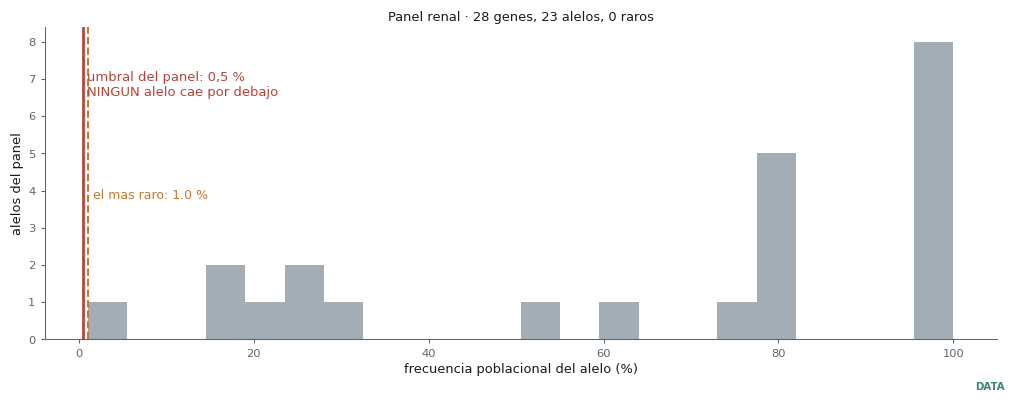

> **Figura principal 3 · el panel renal, en frecuencias**  
> `EXP-017` · figure class `DATA`, figura cientifica · evidence origin `MEASURED`  
> *Interpretacion.* los 23 alelos HIGH/MODERATE del panel son polimorfismos comunes. El mas raro esta al 1.0 %, diez veces por encima del umbral del propio panel. Las dos start_lost de alto impacto que llamaron la atencion estan al 51 % y 81 %. Y MAGED2 no aporta NINGUNA variante (0).  
> **Sesgos que no se corrigen.** que se haya descartado una tubulopatia. Es un barrido CODIFICANTE: no ve variantes reguladoras, intronicas profundas ni estructurales, y esas dependen de EXP-012, bloqueado.  
> procedencia: `config/panels/nephrocalcinosis.txt + cruce de alelos corregido`

In [8]:
fig, ax = plt.subplots(figsize=(9.2, 3.6))
vals = sorted([v.max_af * 100 for v in uniq if v.max_af is not None])
ax.hist(vals, bins=22, color=fl.FLOW, alpha=0.8)
ax.axvline(0.5, color=fl.DEAD, lw=1.8)
ax.text(0.9, ax.get_ylim()[1] * 0.78,
        "umbral del panel: 0,5 %\nNINGUN alelo cae por debajo",
        fontsize=8.6, color=fl.DEAD)
ax.axvline(min(vals), color=fl.OPEN, ls="--", lw=1.3)
ax.text(min(vals) + 0.6, ax.get_ylim()[1] * 0.45, f"el mas raro: {min(vals):.1f} %",
        fontsize=8.2, color=fl.OPEN)
ax.set_xlabel("frecuencia poblacional del alelo (%)")
ax.set_ylabel("alelos del panel")
ax.set_title(f"Panel renal · {len(panel)} genes, {len(uniq)} alelos, 0 raros")

fl.done(fig, "Figura principal 3 · el panel renal, en frecuencias", "EXP-017", "MEASURED", "DATA",
        f"los {len(uniq)} alelos HIGH/MODERATE del panel son polimorfismos comunes. El mas "
        f"raro esta al {min(vals):.1f} %, diez veces por encima del umbral del propio panel. "
        "Las dos start_lost de alto impacto que llamaron la atencion estan al 51 % y 81 %. "
        f"Y MAGED2 no aporta NINGUNA variante ({len(maged2)}).",
        "que se haya descartado una tubulopatia. Es un barrido CODIFICANTE: no ve variantes "
        "reguladoras, intronicas profundas ni estructurales, y esas dependen de EXP-012, "
        "bloqueado.",
        prov="config/panels/nephrocalcinosis.txt + cruce de alelos corregido")

## Robustez · la pregunta que decide no es computacional

`aBS` produce **poli**hidramnios severo desde la semana 18–22. La MVA se asocia a
**oligo**hidramnios. **Son opuestos**: una línea de la historia obstétrica decide.

## Decisión

| Rama | Estado |
|---|---|
| Barrido codificante del panel renal | **NEGATIVE** |
| Crecimiento y fallo de medro como residual | **NEGATIVE**, hueco de anotación |
| Parto prematuro | **PARKED**, contextual, sin cuantificar |
| Atrofia muscular | **PARKED**, sin dato para decidir |
| **Nefrocalcinosis** | **UNRESOLVED · residual prioritario** |

### Qué NO demuestra

No descarta una tubulopatía: el barrido es **codificante**. Y no demuestra que la
nefrocalcinosis sea un segundo diagnóstico, solo que MVA no la describe.

### Falsificador, y es gratis

Ya está en la historia clínica: alcalosis metabólica hipopotasémica e hipoclorémica, renina y
aldosterona elevadas, cociente calcio/creatinina urinario alto. **Si son normales, la hipótesis
muere sin gastar un core-hora.**

### Siguiente movimiento: el de mayor valor de todo el proyecto

**¿Hubo polihidramnios u oligohidramnios en el embarazo?** Es un email.